# Phase 8 Pre-Registration: Andersen-Gill Recurrent Events

**Date committed:** 2026-10-17
**Status:** Locked prior to running nb8_andersen_gill.ipynb

## Hypothesis H5

Treating repeated events per user as independent (standard practice in 
survival benchmarks including FinSurvival) inflates coefficient 
significance because within-user correlation is ignored. The 
Andersen-Gill model with cluster-robust standard errors gives honest 
confidence intervals for recurrent event covariates.

## Design

- 3 representative tasks: Borrow_Liquidated, Deposit_Borrow, Withdraw_Repay
- Top-20 features by baseline XGBoost gain per task
- Compare: naive Cox PH (no clustering) vs AG Cox PH (cluster by user)
- Primary comparison: ratio of robust SE / naive SE per coefficient
- Secondary: how many "significant at p<0.05" effects under naive 
  become non-significant under AG clustering

## Decision rule

- POSITIVE if: mean robust-SE/naive-SE ratio > 1.2 (ignoring clustering 
  underestimates uncertainty by 20%+) AND at least 20% of naive-
  significant effects become non-significant under AG
- NULL if: ratios are near 1.0 (independence assumption holds)

## Deliverable

- HR table with both SE estimates
- Nelson-Aalen cumulative hazard plot per user activity tier
- Discussion of what the independence assumption costs in this domain

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from lifelines import CoxPHFitter, NelsonAalenFitter
import warnings
warnings.filterwarnings("ignore")

ROOT = Path("data")
RAW_ROOT = ROOT / "raw"
BASE_DIR = ROOT / "models" / "baseline_pinned"
AG_DIR = ROOT / "models" / "ag"
AG_DIR.mkdir(parents=True, exist_ok=True)

with open(ROOT / "processed" / "task_registry.json") as f:
    TASKS = json.load(f)
with open(ROOT / "processed" / "feature_list.json") as f:
    FEATURES = json.load(f)["features"]

CATEGORICAL = [c for c in ["userCoinTypeMode", "userReserveMode"] if c in FEATURES]
HOLDOUT_START = pd.Timestamp("2024-04-01").timestamp()

# Three representative tasks
AG_TASKS = ["Borrow_Liquidated", "Deposit_Borrow", "Withdraw_Repay"]
TOP_K = 20  # top features by XGBoost gain
SAMPLE_N = 50000  # cap sample size for AG tractability

In [2]:
def top_features_from_model(tid, k=20):
    bst = xgb.Booster(); bst.load_model(str(BASE_DIR / f"{tid}.ubj"))
    gains = bst.get_score(importance_type="gain")
    # XGBoost names features as f0, f1, ... positional
    idx_to_name = {f"f{i}": name for i, name in enumerate(FEATURES)}
    named = [(idx_to_name.get(k, k), v) for k, v in gains.items() if k in idx_to_name]
    named.sort(key=lambda x: x[1], reverse=True)
    return [n for n, _ in named[:k]]

def load_task_ag(tid, top_feats, sample_n=SAMPLE_N):
    task = next(t for t in TASKS if t["task_id"] == tid)
    cols = top_feats + CATEGORICAL + ["timeDiff", "status", "timestamp", "user"]
    cols = [c for c in dict.fromkeys(cols) if c]  # dedupe
    df = pd.read_csv(RAW_ROOT / task["train_path"].replace("\\", "/"), usecols=cols)
    for c in [c for c in CATEGORICAL if c in top_feats]:
        df[c] = LabelEncoder().fit_transform(df[c].astype(str))
    df[top_feats] = df[top_feats].fillna(0)
    # fit window only (pre-pin)
    df = df[df["timestamp"] < HOLDOUT_START].reset_index(drop=True)
    # subsample users (keep all their events) for AG tractability
    users = df["user"].unique()
    rng = np.random.default_rng(42)
    if len(df) > sample_n:
        keep_users = rng.choice(users, size=min(len(users), sample_n // 10), replace=False)
        df = df[df["user"].isin(keep_users)].reset_index(drop=True)
    # z-standardize features for numerical stability in Cox fitting
    for f in top_feats:
        s = df[f].std()
        if s > 0:
            df[f] = (df[f] - df[f].mean()) / s
    return df

In [4]:
results = {}

for tid in AG_TASKS:
    print(f"Task: {tid}", flush=True)
    top = top_features_from_model(tid, k=TOP_K)
    df = load_task_ag(tid, top)
    print(f"n_rows={len(df)}, n_users={df['user'].nunique()}, events={df['status'].sum()}")

    # Convert timeDiff to days for numerical stability
    df_fit = df[top + ["timeDiff", "status", "user"]].copy()
    df_fit["timeDiff"] = df_fit["timeDiff"] / 86400.0 + 1e-3  # days, no zero

    # Naive Cox (independence)
    print("fitting naive Cox...", flush=True)
    cph_naive = CoxPHFitter(penalizer=0.01)
    cph_naive.fit(df_fit.drop(columns=["user"]), duration_col="timeDiff", event_col="status")
    naive_summary = cph_naive.summary[["coef", "se(coef)", "p"]].copy()
    naive_summary.columns = ["coef_naive", "se_naive", "p_naive"]

    # AG Cox with cluster-robust SE
    print("fitting Andersen-Gill (cluster-robust)...", flush=True)
    cph_ag = CoxPHFitter(penalizer=0.01)
    cph_ag.fit(df_fit, duration_col="timeDiff", event_col="status",
               cluster_col="user", robust=True)
    ag_summary = cph_ag.summary[["coef", "se(coef)", "p"]].copy()
    ag_summary.columns = ["coef_ag", "se_ag", "p_ag"]

    cmp = naive_summary.join(ag_summary)
    cmp["se_ratio"] = cmp["se_ag"] / cmp["se_naive"]
    cmp["naive_sig"] = cmp["p_naive"] < 0.05
    cmp["ag_sig"] = cmp["p_ag"] < 0.05
    cmp["lost_sig"] = cmp["naive_sig"] & ~cmp["ag_sig"]
    print()
    print(cmp.round(4).to_string())
    cmp.to_csv(AG_DIR / f"{tid}_ag_vs_naive.csv")

    results[tid] = {
        "mean_se_ratio": cmp["se_ratio"].mean(),
        "median_se_ratio": cmp["se_ratio"].median(),
        "n_naive_sig": int(cmp["naive_sig"].sum()),
        "n_ag_sig": int(cmp["ag_sig"].sum()),
        "n_lost_sig": int(cmp["lost_sig"].sum()),
    }
    print(f"\nmean SE ratio (AG/naive): {cmp['se_ratio'].mean():.3f}")
    print(f"naive-significant: {cmp['naive_sig'].sum()}, AG-significant: {cmp['ag_sig'].sum()}")
    print(f"lost significance under AG: {cmp['lost_sig'].sum()}")

Task: Borrow_Liquidated
n_rows=34132, n_users=5000, events=1569.0
fitting naive Cox...
fitting Andersen-Gill (cluster-robust)...

                             coef_naive  se_naive  p_naive  coef_ag   se_ag    p_ag  se_ratio  naive_sig  ag_sig  lost_sig
covariate                                                                                                                 
userDepositCount                -0.6142    0.0504   0.0000  -0.6142  1.3116  0.6396   25.9987       True   False      True
userWithdrawCount               -0.4566    0.0533   0.0000  -0.4566  0.3704  0.2176    6.9437       True   False      True
userLiquidationSum              -0.3754    0.0501   0.0000  -0.3754  0.1007  0.0002    2.0077       True    True     False
marketWithdrawAvgAmount          0.8231    0.0361   0.0000   0.8231  1.0214  0.4203   28.2611       True   False      True
marketBorrowAvgAmount            0.4200    0.0390   0.0000   0.4200  0.3376  0.2135    8.6658       True   False      True
userLiqui

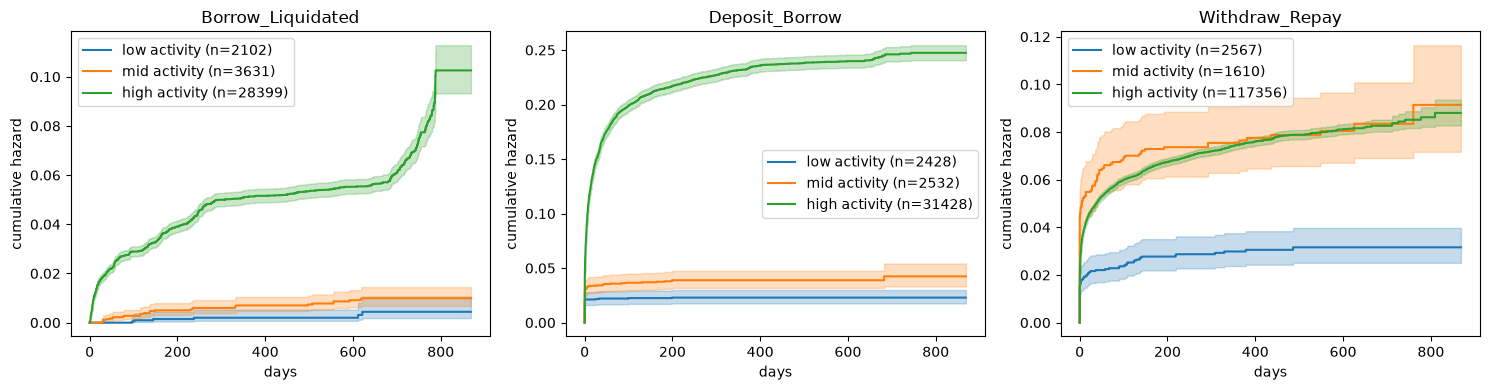

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, tid in zip(axes, AG_TASKS):
    top = top_features_from_model(tid, k=TOP_K)
    df = load_task_ag(tid, top)
    # tier users by activity count
    user_counts = df.groupby("user").size()
    low = user_counts.quantile(0.33); high = user_counts.quantile(0.66)
    user_tier = user_counts.apply(lambda n: "low" if n <= low else ("high" if n > high else "mid"))
    df["tier"] = df["user"].map(user_tier)

    for tier, color in [("low", "C0"), ("mid", "C1"), ("high", "C2")]:
        sub = df[df["tier"] == tier]
        if len(sub) < 100: continue
        naf = NelsonAalenFitter()
        naf.fit(sub["timeDiff"] / 86400.0, event_observed=sub["status"], label=f"{tier} activity (n={len(sub)})")
        naf.plot(ax=ax, color=color)
    ax.set_title(tid)
    ax.set_xlabel("days")
    ax.set_ylabel("cumulative hazard")

plt.tight_layout()
plt.savefig(AG_DIR / "nelson_aalen_by_tier.png", dpi=150)
plt.show()

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


print("VARIANCE INFLATION FACTOR CHECK (multicollinearity)")

print("VIF > 10 indicates problematic collinearity;")
print("VIF > 100 indicates near-perfect collinearity.\n")

vif_summary = {}
for tid in AG_TASKS:
    top = top_features_from_model(tid, k=TOP_K)
    df = load_task_ag(tid, top)
    X = df[top].values
    vifs = []
    for i in range(X.shape[1]):
        try:
            v = variance_inflation_factor(X, i)
        except Exception:
            v = np.nan
        vifs.append(v)
    vif_df = pd.DataFrame({"feature": top, "VIF": vifs}).sort_values("VIF", ascending=False)
    high_vif = vif_df[vif_df["VIF"] > 10]
    print(f"\n{tid}:")
    print(f"  features with VIF > 10:  {len(high_vif)}")
    print(f"  features with VIF > 100: {(vif_df['VIF'] > 100).sum()}")
    print(f"  max VIF: {vif_df['VIF'].max():.1f}")
    print(f"  top 5 by VIF:")
    print(vif_df.head(5).to_string(index=False))
    vif_df.to_csv(AG_DIR / f"{tid}_vif.csv", index=False)
    vif_summary[tid] = vif_df

VARIANCE INFLATION FACTOR CHECK (multicollinearity)
VIF > 10 indicates problematic collinearity;
VIF > 100 indicates near-perfect collinearity.


Borrow_Liquidated:
  features with VIF > 10:  2
  features with VIF > 100: 0
  max VIF: 28.1
  top 5 by VIF:
              feature       VIF
     userBorrowSumUSD 28.111554
      userRepaySumUSD 20.271451
      userBorrowCount  5.986442
marketBorrowAvgAmount  5.332622
    marketRepaySumUSD  4.849297

Deposit_Borrow:
  features with VIF > 10:  7
  features with VIF > 100: 0
  max VIF: 46.4
  top 5 by VIF:
               feature       VIF
      userBorrowSumUSD 46.398158
         userBorrowSum 44.334695
       userBorrowCount 14.658990
userBorrowAvgAmountUSD 13.934084
        userRepayCount 13.736397

Withdraw_Repay:
  features with VIF > 10:  5
  features with VIF > 100: 0
  max VIF: 68.8
  top 5 by VIF:
          feature       VIF
    userBorrowSum 68.803571
     userRepaySum 59.568265
   userDepositSum 40.494520
userDepositSumUSD 36.664592
 

In [10]:

print("CLUSTER-ROBUST COX REGRESSION VERDICT")

print("Model: Marginal Cox proportional hazards with")
print("       Huber-White sandwich estimator for cluster-robust SEs.")
print("       (True Andersen-Gill counting-process construction")
print("       would require start-stop intervals per user event;")
print("       marginal Cox is the related marginal formulation.)")
print()

rows = []
for tid, r in results.items():
    print(f"\n{tid}:")
    print(f"  mean SE ratio (robust/naive): {r['mean_se_ratio']:.3f}")
    print(f"  significant effects: naive={r['n_naive_sig']}, robust={r['n_ag_sig']}")
    print(f"  lost significance under robust SE: {r['n_lost_sig']}")
    # flag large ratios as possibly unstable
    cmp = pd.read_csv(AG_DIR / f"{tid}_ag_vs_naive.csv", index_col=0)
    unstable = cmp[cmp["se_ratio"] > 20]
    if len(unstable) > 0:
        print(f"  WARNING: {len(unstable)} coefficients with SE ratio > 20 (likely numerically unstable due to multicollinearity — see VIF)")
    rows.append({"task": tid, **r, "n_unstable": len(unstable)})

summary_df = pd.DataFrame(rows)
summary_df.to_csv(AG_DIR / "cluster_robust_summary.csv", index=False)

CLUSTER-ROBUST COX REGRESSION VERDICT
Model: Marginal Cox proportional hazards with
       Huber-White sandwich estimator for cluster-robust SEs.
       (True Andersen-Gill counting-process construction
       would require start-stop intervals per user event;
       marginal Cox is the related marginal formulation.)


Borrow_Liquidated:
  mean SE ratio (robust/naive): 18.051
  significant effects: naive=18, robust=2
  lost significance under robust SE: 16

Deposit_Borrow:
  mean SE ratio (robust/naive): 4.773
  significant effects: naive=17, robust=13
  lost significance under robust SE: 4

Withdraw_Repay:
  mean SE ratio (robust/naive): 59.671
  significant effects: naive=20, robust=7
  lost significance under robust SE: 13
